# 02 — Дослідження ознак та підготовка даних
TUKE OZ · CRISP-DM: Data Understanding → Data Preparation

Мета: дослідити розподіли, відокремити ID та підготувати числовий baseline для кластеризації. Цільових міток немає.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image, Markdown
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'src/preprocessing.py').exists(), 'Запусти з кореня проєкту або notebooks/'
sys.path.insert(0, str(ROOT / 'src'))
from preprocessing import prepare

Matplotlib is building the font cache; this may take a moment.


## Рішення
- `id` зберігаємо окремо, але виключаємо з ознак.
- `f_07`–`f_13` цілочисельні. Без словника ознак їхня семантика невідома. Числові відстані між їхніми значеннями — припущення цього baseline. Якщо це номінальні категорії, потрібен окремий варіант кодування й порівняння.
- Немає пропусків і дублікатів; перевіряємо придатність даних повторно.
- Правило 1.5 IQR позначає хвости розподілу, а не доведені помилки. Викиди можуть належати справжнім кластерам. Нічого не видаляємо й не обрізаємо.

In [2]:
profile, pairs, summary = prepare(ROOT)
display(profile)
display(summary)

,dtype,unique,min,max,mean,std_population,skew,iqr,outside_1_5_iqr_count,outside_1_5_iqr_percent,observed_type
feature,,,,,,,,,,,
f_00,float64,98000,-4.732235,4.490521,0.001220,1.002796,0.002451,1.352497,692,0.706122,continuous_candidate
f_01,float64,98000,-4.202795,4.324974,0.005580,1.000737,0.005256,1.348731,718,0.732653,continuous_candidate
f_02,float64,98000,-4.377021,4.560247,-0.001042,1.001368,-0.010418,1.349865,698,0.712245,continuous_candidate
f_03,float64,98000,-4.010826,4.399373,-0.000700,1.000417,0.012110,1.344637,701,0.715306,continuous_candidate
f_04,float64,98000,-4.535903,4.050549,-0.003522,1.003056,-0.001219,1.360098,652,0.665306,continuous_candidate
f_05,float64,98000,-4.300767,4.710316,-0.001612,1.000526,-0.001270,1.348410,664,0.677551,continuous_candidate
f_06,float64,98000,-4.894525,3.998595,-0.003042,0.997429,0.013073,1.348534,629,0.641837,continuous_candidate
f_07,int64,32,0.000000,32.000000,5.545918,3.691821,0.797179,5.000000,1188,1.212245,integer_discrete_candidate
f_08,int64,29,0.000000,30.000000,6.763061,4.152327,0.545605,5.000000,1805,1.841837,integer_discrete_candidate


{'source': '/Users/rostyslav/uui/oz/zadanie/ozsuhakmatsko/data/data.csv',
 'source_sha256': '549a4d597814360932bcc76ef5f876c02944d0d508d709fe617b893ccda654eb',
 'rows': 98000,
 'features': 29,
 'excluded_columns': ['id'],
 'integer_candidates': ['f_07',
  'f_08',
  'f_09',
  'f_10',
  'f_11',
  'f_12',
  'f_13'],
 'continuous_candidates': ['f_00',
  'f_01',
  'f_02',
  'f_03',
  'f_04',
  'f_05',
  'f_06',
  'f_14',
  'f_15',
  'f_16',
  'f_17',
  'f_18',
  'f_19',
  'f_20',
  'f_21',
  'f_22',
  'f_23',
  'f_24',
  'f_25',
  'f_26',
  'f_27',
  'f_28'],
 'rows_outside_iqr_in_any_feature': 24391,
 'removed_rows': 0,
 'max_absolute_off_diagonal_pearson': 0.3607338943092746,
 'assumption': 'Integer features treated as numeric for this baseline; categorical semantics unconfirmed.',
 'fit_scope': 'All rows, transductive clustering; no held-out evaluation claimed.',
 'versions': {'python': '3.9.6',
  'numpy': '2.0.2',
  'pandas': '2.3.3',
  'sklearn': '1.6.1',
  'matplotlib': '3.9.4'}}

## Розподіли
Використано всі рядки. Для цілочисельних ознак показано точні частоти. Форма розподілу сама по собі не доводить кількості кластерів або корисності ознаки.

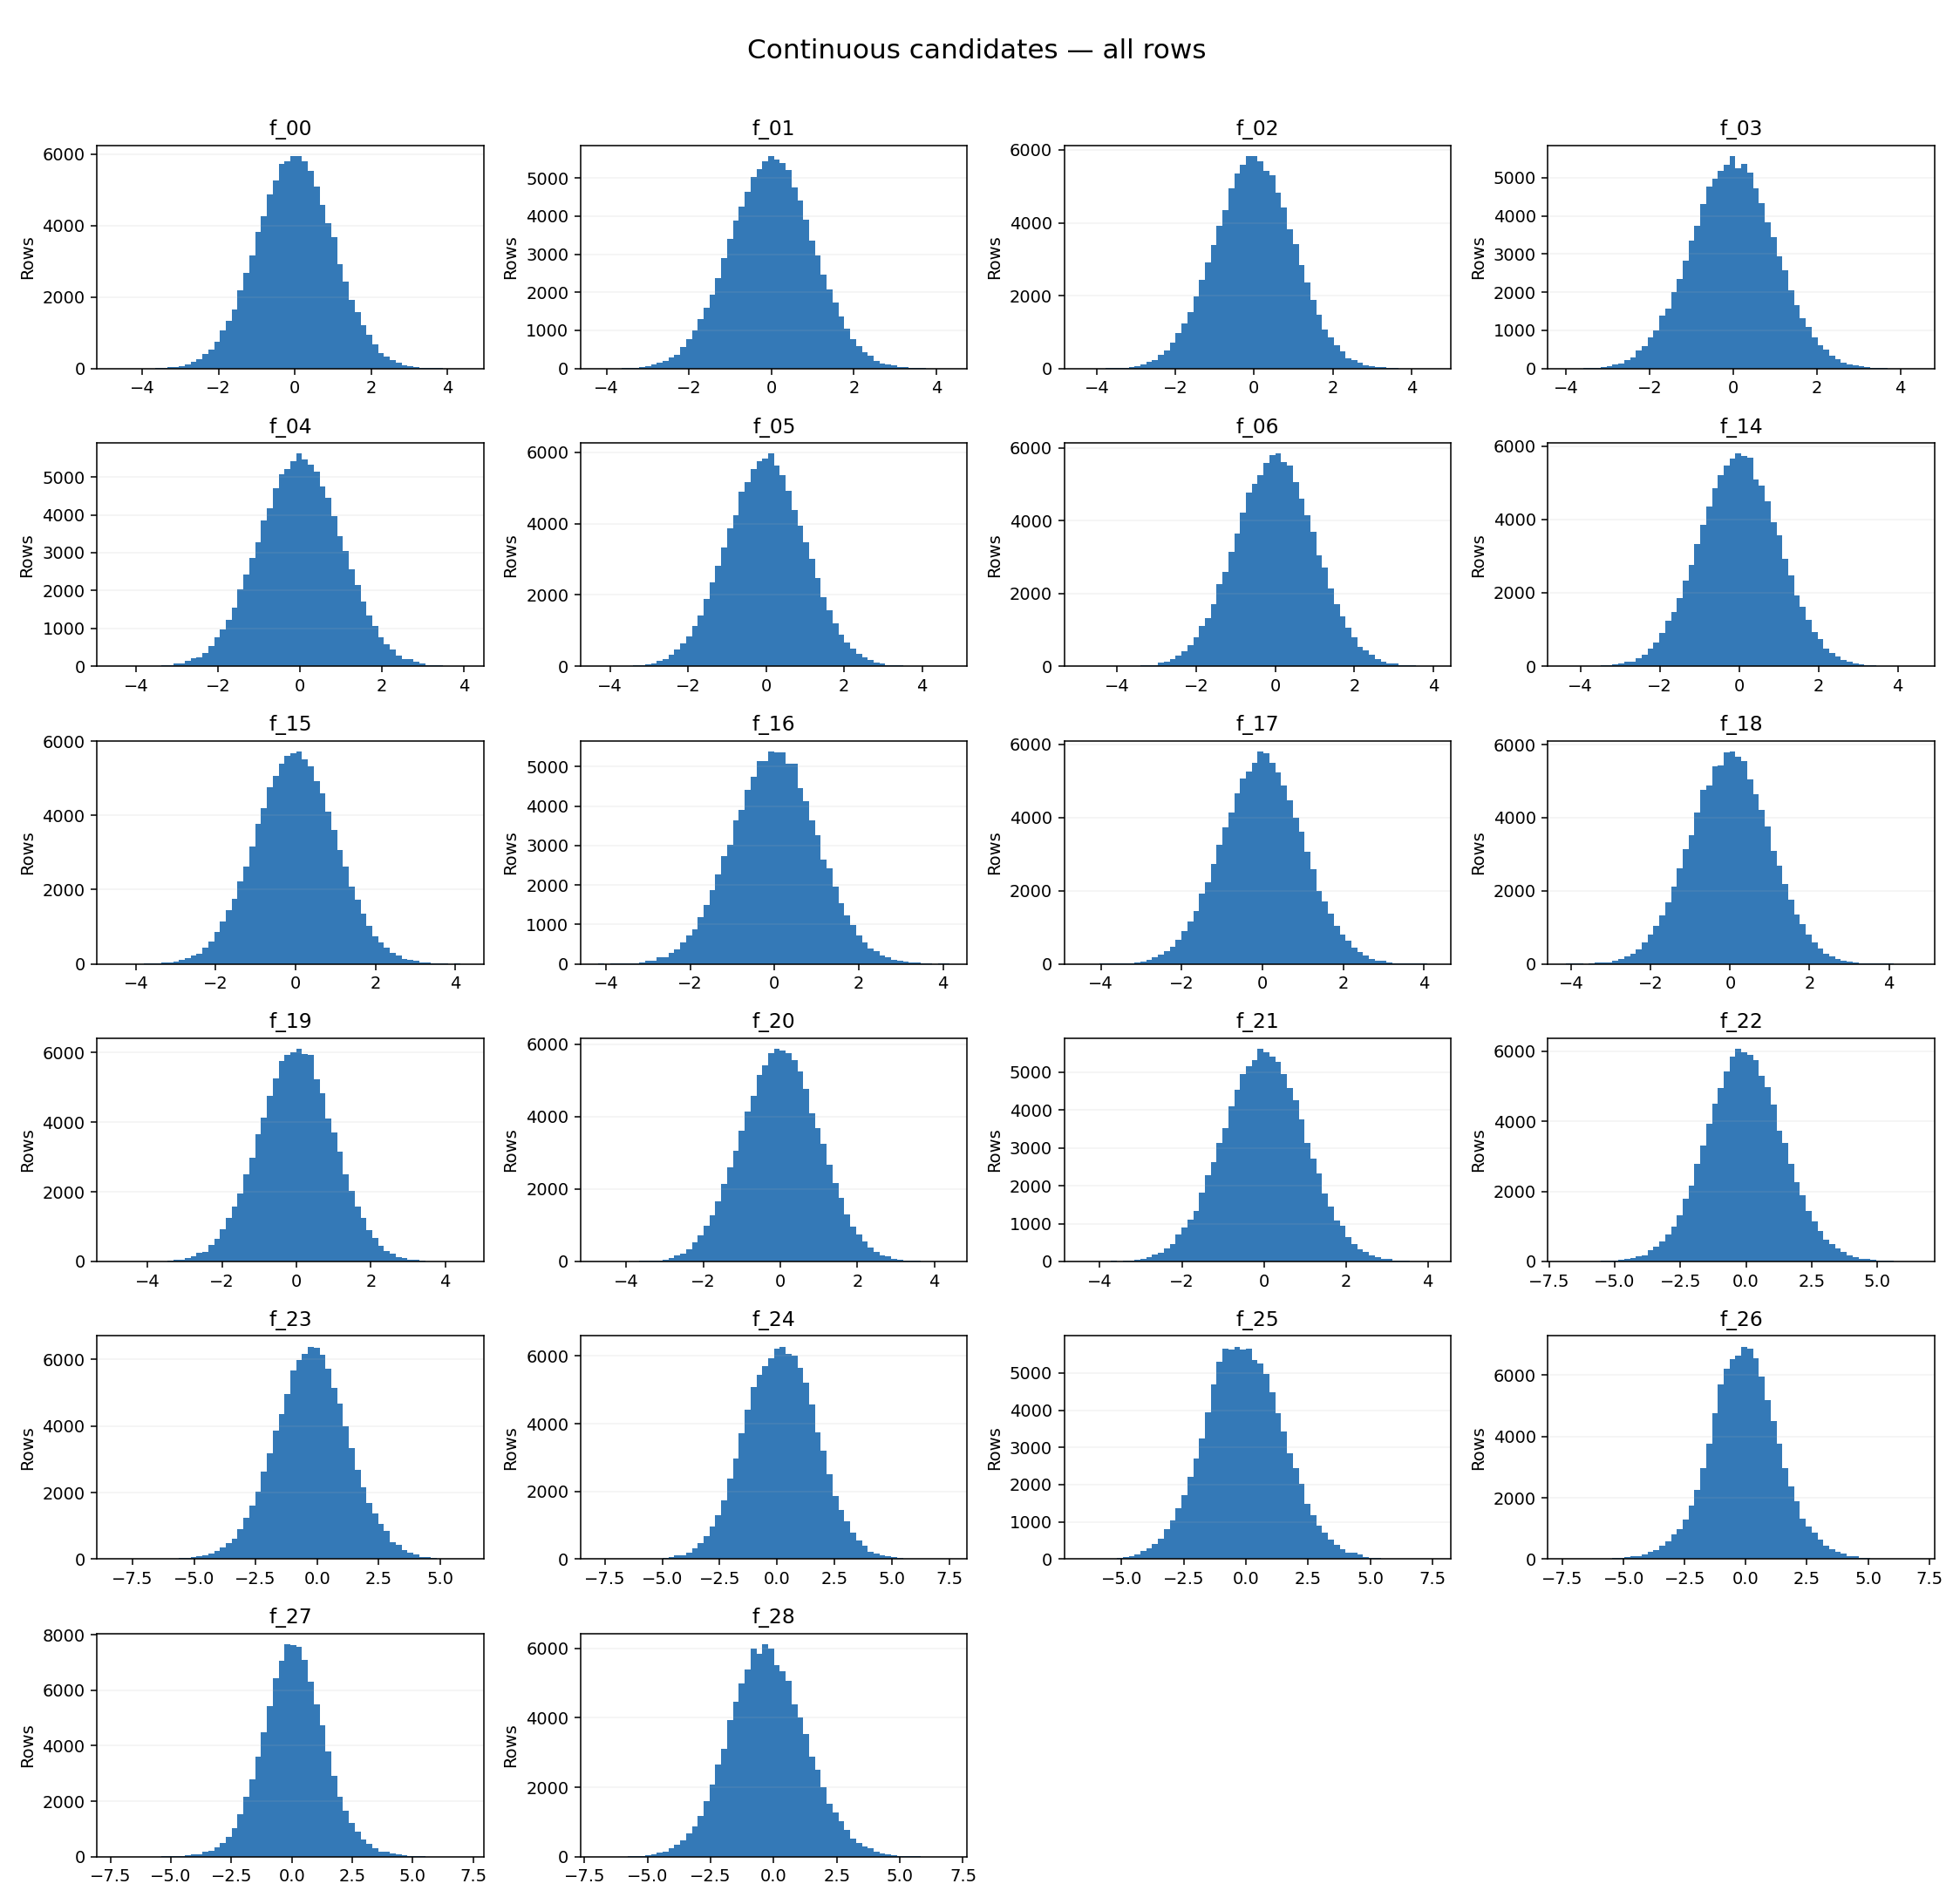

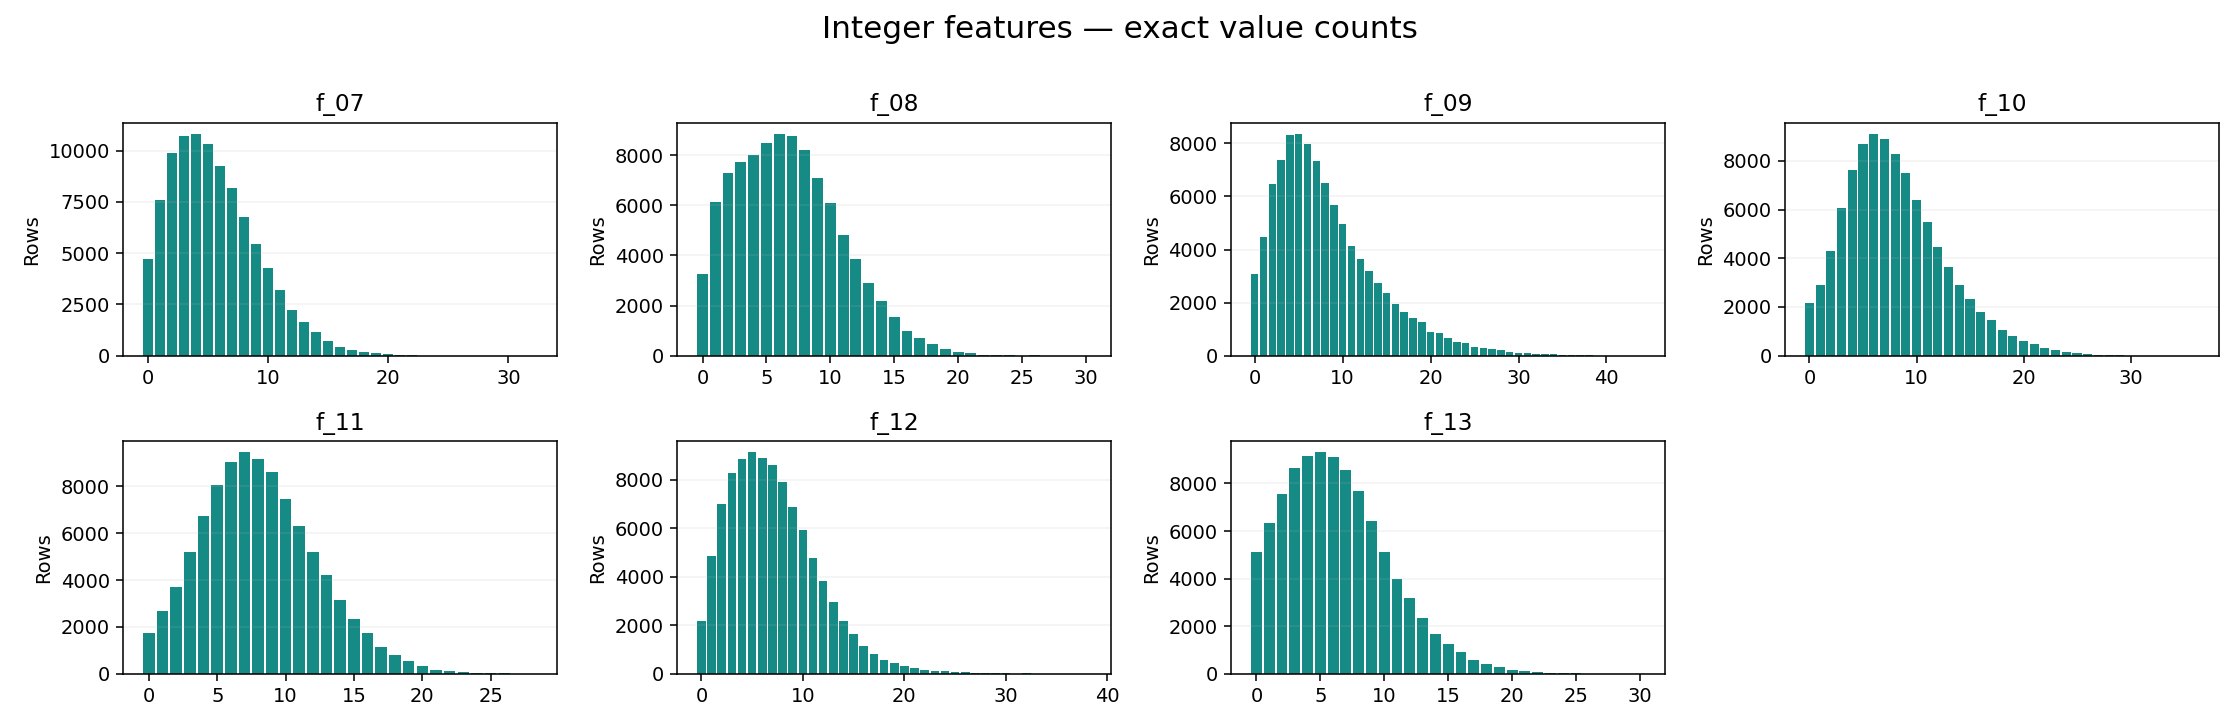

In [3]:
for name in ['continuous_distributions.png', 'discrete_distributions.png']:
    display(Image(filename=str(ROOT / 'reports/preprocessing' / name)))

## Кореляції
Pearson показує лінійний зв’язок. Слабка кореляція не виключає нелінійних зв’язків чи кластерної структури. Ознаки через кореляцію поки не видаляємо.

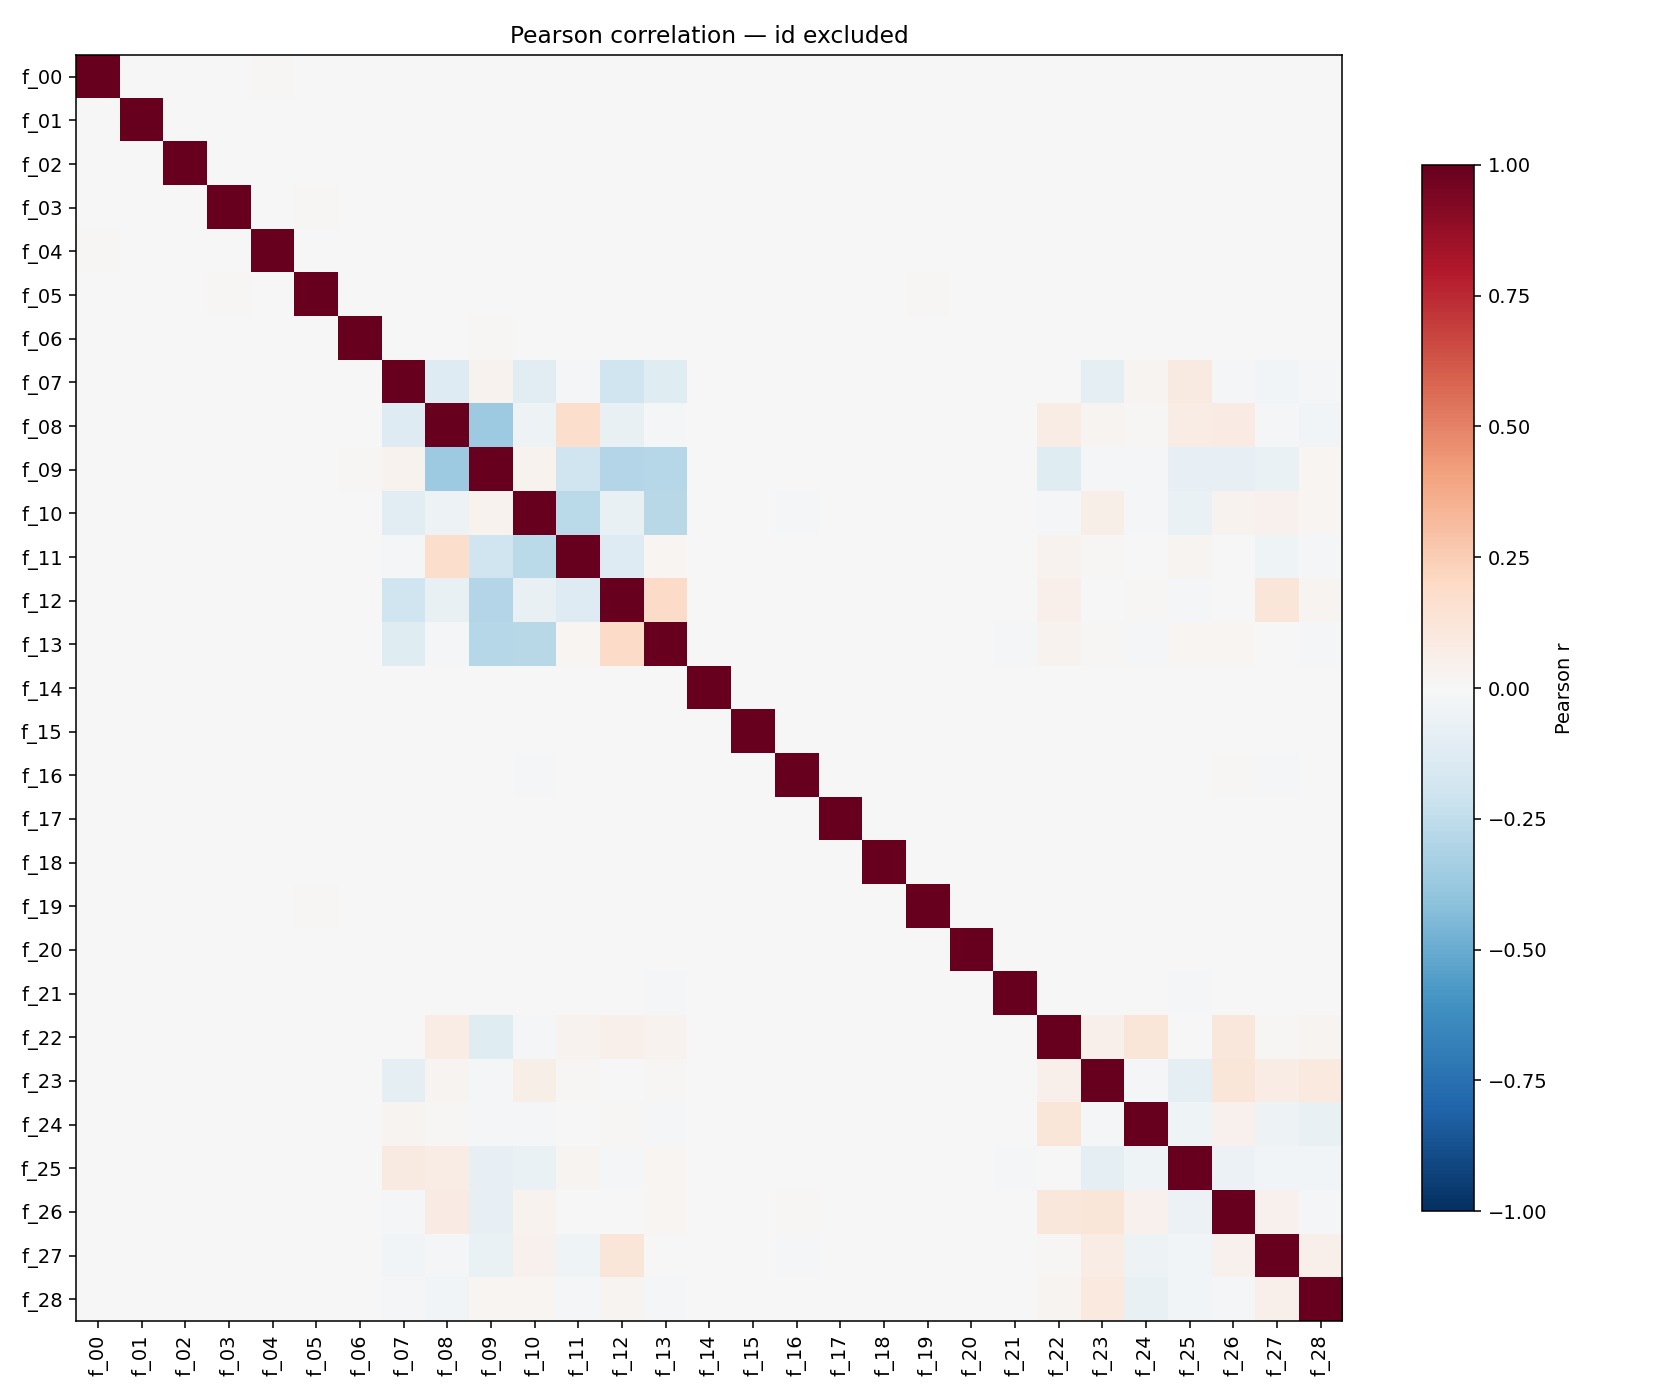

,feature_a,feature_b,pearson_r,absolute_r
0,f_08,f_09,-0.360734,0.360734
1,f_09,f_12,-0.295563,0.295563
2,f_09,f_13,-0.281970,0.281970
3,f_10,f_13,-0.281057,0.281057
4,f_10,f_11,-0.267171,0.267171
5,f_09,f_11,-0.202523,0.202523
6,f_07,f_12,-0.196534,0.196534
7,f_12,f_13,0.195191,0.195191
8,f_08,f_11,0.179527,0.179527
9,f_07,f_08,-0.131742,0.131742


In [4]:
display(Image(filename=str(ROOT / 'reports/preprocessing/correlations.png')))
display(pairs.head(10))

## Масштабування
StandardScaler: z = (x − mean) / scale; середнє приблизно 0 і стандартне відхилення 1 (ddof=0). Це початковий спосіб зробити масштаби порівнянними, а не гарантія оптимальних кластерів.

Scaler навчено на всіх рядках для **трансдуктивної кластеризації цього набору**. Для оцінювання на нових/відкладених даних потрібно спочатку виконати поділ і навчити scaler тільки на тренувальній частині. Поточна матриця не є незалежним test-набором.

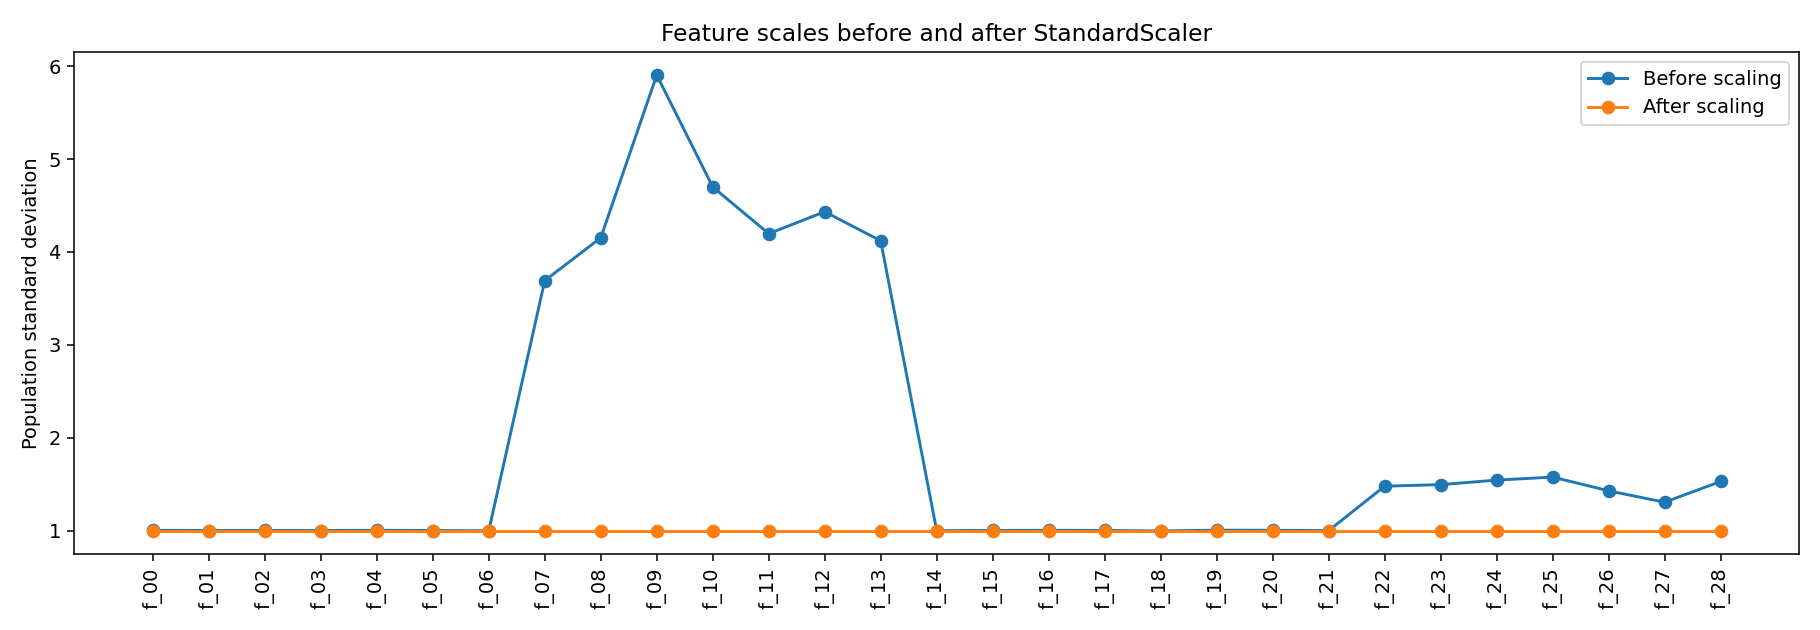

,feature,mean_before,std_before,mean_after,std_after
0,f_00,0.001220,1.002796,-2.943677e-17,1.0
1,f_01,0.005580,1.000737,-3.132188e-17,1.0
2,f_02,-0.001042,1.001368,-2.225884e-17,1.0
3,f_03,-0.000700,1.000417,-5.002801e-18,1.0
4,f_04,-0.003522,1.003056,1.725604e-17,1.0
5,f_05,-0.001612,1.000526,1.827110e-17,1.0
6,f_06,-0.003042,0.997429,2.465148e-18,1.0
7,f_07,5.545918,3.691821,-7.047424e-17,1.0
8,f_08,6.763061,4.152327,-3.364202e-17,1.0
9,f_09,8.193163,5.904889,4.741785e-17,1.0


In [5]:
display(Image(filename=str(ROOT / 'reports/preprocessing/scaling.png')))
import pandas as pd
display(pd.read_csv(ROOT / 'reports/preprocessing/scaling_check.csv'))

## Файли та перевірки
`data/processed/numeric_standardized.npz`: матриця X, вихідні ids, порядок columns.
`scaler_parameters.json`: середні, масштаби та порядок ознак.

Перевірено скінченність, середнє/масштаб, зворотне перетворення, порядок рядків та незмінність сирого CSV. Завантаження не потребує pickle.

In [6]:
import numpy as np
with np.load(ROOT / 'data/processed/numeric_standardized.npz', allow_pickle=False) as data:
    X = data['X']
    ids = data['ids']
    columns = data['columns']
print('Матриця:', X.shape)
print('ID:', ids.shape)
print('Ознаки:', columns.tolist())
print('Максимальна абсолютна парна кореляція:', round(summary['max_absolute_off_diagonal_pearson'], 3))
print('Рядки за межами 1.5 IQR хоча б в одній ознаці:', summary['rows_outside_iqr_in_any_feature'])
print('Видалено рядків:', summary['removed_rows'])

Матриця: (98000, 29)
ID: (98000,)
Ознаки: ['f_00', 'f_01', 'f_02', 'f_03', 'f_04', 'f_05', 'f_06', 'f_07', 'f_08', 'f_09', 'f_10', 'f_11', 'f_12', 'f_13', 'f_14', 'f_15', 'f_16', 'f_17', 'f_18', 'f_19', 'f_20', 'f_21', 'f_22', 'f_23', 'f_24', 'f_25', 'f_26', 'f_27', 'f_28']
Максимальна абсолютна парна кореляція: 0.361
Рядки за межами 1.5 IQR хоча б в одній ознаці: 24391
Видалено рядків: 0


## Далі
Порівняємо K-Means і Gaussian Mixture для кількох k, перевіримо якість, розміри й стабільність кластерів. Без еталонних міток не обчислюємо Accuracy або ROC-AUC. Альтернативне масштабування/трактування дискретних ознак варто порівняти на етапі моделей.